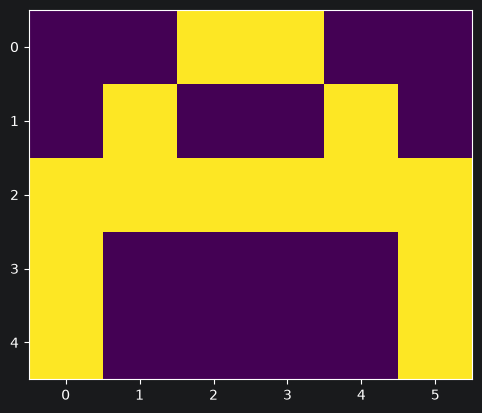

In [2]:
import numpy as np
import matplotlib.pyplot as plt
# Creating data set

# A
a =[0, 0, 1, 1, 0, 0,
   0, 1, 0, 0, 1, 0,
   1, 1, 1, 1, 1, 1,
   1, 0, 0, 0, 0, 1,
   1, 0, 0, 0, 0, 1]
# B
b =[0, 1, 1, 1, 1, 0,
   0, 1, 0, 0, 1, 0,
   0, 1, 1, 1, 1, 0,
   0, 1, 0, 0, 1, 0,
   0, 1, 1, 1, 1, 0]
# C
c =[0, 1, 1, 1, 1, 0,
   0, 1, 0, 0, 0, 0,
   0, 1, 0, 0, 0, 0,
   0, 1, 0, 0, 0, 0,
   0, 1, 1, 1, 1, 0]

# Creating labels
y =[[1, 0, 0],
   [0, 1, 0],
   [0, 0, 1]]

# visualizing the data, plotting A.
plt.imshow(np.array(a).reshape(5, 6))
plt.show()

In [3]:
# converting data and labels into numpy array
x =[np.array(a).reshape(1, 30), np.array(b).reshape(1, 30),
                                np.array(c).reshape(1, 30)]
y = np.array(y)
# Printing data and labels
print(x, "\n\n", y)

[array([[0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0,
        0, 1, 1, 0, 0, 0, 0, 1]]), array([[0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0,
        1, 0, 0, 1, 1, 1, 1, 0]]), array([[0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0,
        0, 0, 0, 1, 1, 1, 1, 0]])] 

 [[1 0 0]
 [0 1 0]
 [0 0 1]]


In [4]:
# activation function
def sigmoid(x):
	return 1/(1 + np.exp(-x))

# Creating the Feed forward neural network
def f_forward(x, w1, w2):
	print(x.shape, w1.shape, w2.shape)
	z1 = x.dot(w1)    # input from layer 1
	a1 = sigmoid(z1)  # out put of layer 2
	z2 = a1.dot(w2)   # input of out layer
	a2 = sigmoid(z2)  # output of out layer
	print(a2.shape)
	return a2

# initializing the weights randomly
def generate_wt(x, y):
	li =[]
	for i in range(x * y):
		li.append(np.random.randn())
	return np.array(li).reshape(x, y)

# for loss we will be using mean square error(MSE)
def loss(out, Y):
	s =(np.square(out-Y))
	s = np.sum(s)/len(y)
	return s

# Back propagation of error
def back_prop(inputs, targets, weights_hidden, weights_output, learning_rate):
    """
    Performs backpropagation and gradient descent parameter updates.

    Parameters:
        inputs: Input feature matrix (X)
        targets: Ground-truth one-hot encoded labels (Y)
        weights_hidden: Weight matrix between input and hidden layer (W1)
        weights_output: Weight matrix between hidden and output layer (W2)
        learning_rate: Step size scalar (alpha)

    Returns:
        Updated weights_hidden, weights_output
    """
    # 1. Forward pass activations
    hidden_activations = sigmoid(inputs.dot(weights_hidden))
    predicted_output = sigmoid(hidden_activations.dot(weights_output))

    # 2. Output layer error signal
    output_delta = predicted_output - targets

    # 3. Propagate error to hidden layer through activation derivative
    hidden_activation_derivative = hidden_activations * (1 - hidden_activations)
    hidden_error_signal = weights_output.dot(output_delta.T).T
    hidden_delta = hidden_error_signal * hidden_activation_derivative

    # 4. Compute parameter gradients
    grad_weights_hidden = inputs.T.dot(hidden_delta)
    grad_weights_output = hidden_activations.T.dot(output_delta)

    # 5. Gradient descent parameter update
    weights_hidden = weights_hidden - (learning_rate * grad_weights_hidden)
    weights_output = weights_output - (learning_rate * grad_weights_output)

    return weights_hidden, weights_output

In [5]:
w1 = generate_wt(30, 5)
w2 = generate_wt(5, 3)

print(w1, "\n\n", w2)

[[-6.28359933e-01 -9.80321578e-01 -4.89977894e-01 -2.55433599e-01
  -1.18946132e+00]
 [ 9.19810487e-01 -7.59850816e-01 -6.64296262e-01 -1.51521510e+00
  -1.88855317e+00]
 [-7.46357813e-03  8.52239459e-01 -6.19028683e-01 -7.54413862e-01
  -3.76548409e-01]
 [ 1.80010933e+00 -6.99185956e-01 -8.10952404e-01  1.27008294e+00
  -6.67542998e-01]
 [ 6.88595374e-01  1.53763336e+00 -1.13198389e-01  1.25848882e+00
   3.21756019e-01]
 [-6.01500758e-01  1.16838788e+00  8.56882280e-01 -1.54901558e+00
  -6.67855695e-02]
 [-4.81542467e-01  4.14331006e-01 -3.92726519e-01  9.73772711e-01
   2.93303106e-01]
 [ 3.67868921e-01 -1.12469382e+00  8.33559692e-01  1.94927169e+00
   2.26129261e+00]
 [-6.99974453e-02  1.15399819e+00 -1.59043699e+00  2.73175033e-01
  -7.02460780e-01]
 [ 8.62228852e-01 -2.20424624e-01 -1.24159352e+00 -6.90955694e-01
  -1.81995829e-01]
 [-2.05550497e+00 -6.67291626e-01 -2.98553953e-01 -3.70246851e-01
  -1.58384429e+00]
 [-1.77273124e+00  9.50968772e-01 -2.74791653e+00  1.56247274e+00

(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
HERE 3 3
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
HERE 3 3
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
HERE 3 3
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
HERE 3 3
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
HERE 3 3
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
HERE 3 3
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
HERE 3 3
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
HERE 3 3
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
HERE 3 3
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
(1, 30) (30, 5) (5, 3)
(1, 3)
HERE 3 3
(1, 30) (3

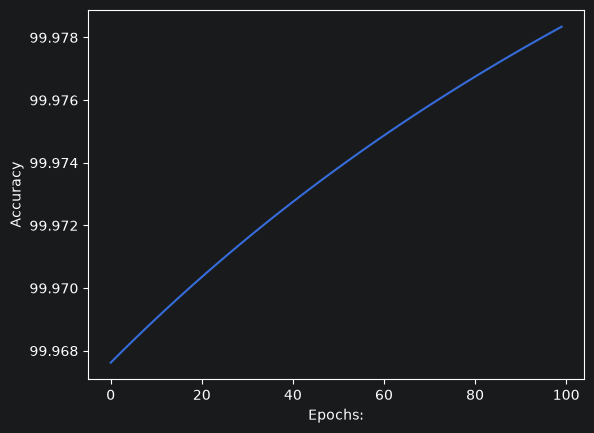

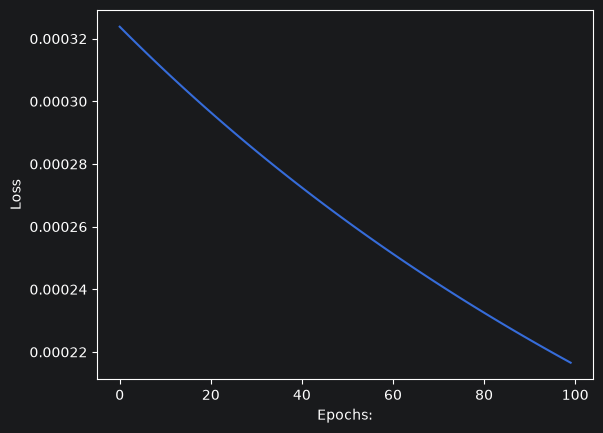

In [12]:
def train(x, Y, w1, w2, alpha = 0.01, epoch = 10):
	acc =[]
	losss =[]
	for j in range(epoch):
		l =[]
		for i in range(len(x)):
			out = f_forward(x[i], w1, w2)
			l.append(loss(out, Y[i]))
			w1, w2 = back_prop(x[i], y[i], w1, w2, alpha)
			#if j % 10000 == 0:
				#print("epochs:", j + 1, "======== acc:", (1-(sum(l)/len(x)))*100)
		print("HERE",len(x), len(l))
		acc.append((1-(sum(l)/len(x)))*100)
		losss.append(sum(l)/len(x))
	return acc, losss, w1, w2

acc, losss, w1, w2 = train(x, y, w1, w2, 0.1, 100)


# plotting accuracy
plt.plot(acc)
plt.ylabel('Accuracy')
plt.xlabel("Epochs:")
plt.show()

# plotting Loss
plt.plot(losss)
plt.ylabel('Loss')
plt.xlabel("Epochs:")
plt.show()

Image is of letter A.


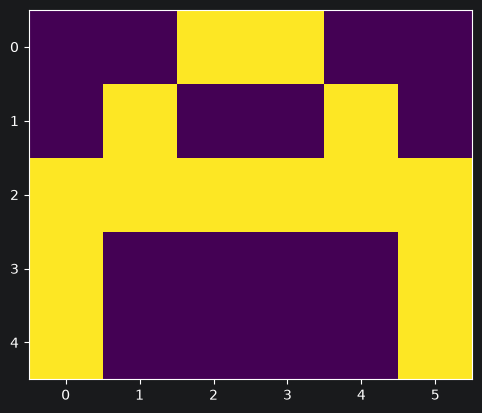

Image is of letter B.


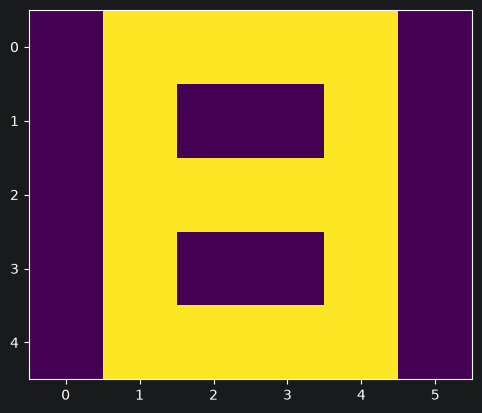

Image is of letter C.


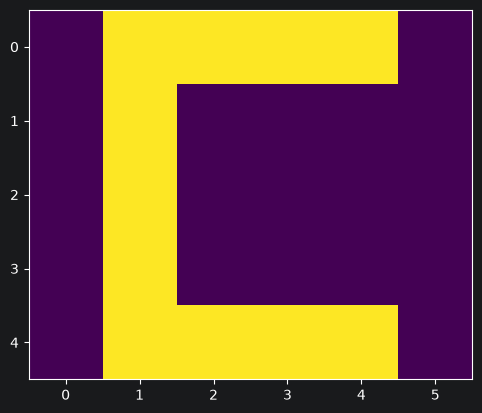

In [7]:
def predict(x, w1, w2):
	Out = f_forward(x, w1, w2)
	maxm = 0
	k = 0
	for i in range(len(Out[0])):
		if(maxm<Out[0][i]):
			maxm = Out[0][i]
			k = i
	if k == 0:
		print("Image is of letter A.")
	elif k == 1:
		print("Image is of letter B.")
	else:
		print("Image is of letter C.")
	plt.imshow(x.reshape(5, 6))
	plt.show()
# Example: Predicting for letter 'B'
for i in range(3):
	predict(x[i], w1, w2)